### Import Libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
import joblib

### Load Dataset

In [3]:
data = pd.read_csv('email_spam_detection.csv')

In [4]:
data.head()

,Email_ID,Sender_Email,Subject,Email_Length,Num_Links,Num_Special_Chars,Capital_Words,Has_Attachment,Spam
0,1,,Meeting,NaN,99,-1,7,0,0
1,2,user1@outlook.com,Security Alert,87.0,2,3,8,0,0
2,3,user2@yahoo.com,Win Prize,69.0,0,3,8,0,0
3,4,user3@gmail.com,Invoice,61.0,0,3,8,0,0
4,5,user4@company.com,Meeting,99.0,2,3,5,0,0


In [5]:
data.tail()

,Email_ID,Sender_Email,Subject,Email_Length,Num_Links,Num_Special_Chars,Capital_Words,Has_Attachment,Spam
6995,6996,user6995@gmail.com,Greetings,93.0,1,2,6,1,0
6996,6997,user6996@yahoo.com,Offer,107.0,0,0,7,0,0
6997,6998,user6997@gmail.com,Account Verification,222.0,7,14,17,0,1
6998,6999,user6998@outlook.com,Win Prize,164.0,6,16,8,1,1
6999,7000,user6999@company.com,Greetings,168.0,1,17,55,1,1


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Email_ID           7000 non-null   int64  
 1   Sender_Email       6999 non-null   str    
 2   Subject            7000 non-null   str    
 3   Email_Length       6959 non-null   float64
 4   Num_Links          7000 non-null   int64  
 5   Num_Special_Chars  7000 non-null   int64  
 6   Capital_Words      7000 non-null   int64  
 7   Has_Attachment     7000 non-null   int64  
 8   Spam               7000 non-null   int64  
dtypes: float64(1), int64(6), str(2)
memory usage: 694.4 KB


In [7]:
data.describe()

,Email_ID,Email_Length,Num_Links,Num_Special_Chars,Capital_Words,Has_Attachment,Spam
count,7000.000000,6959.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000
mean,3500.500000,110.567898,2.454571,6.636429,12.199714,0.260714,0.305143
std,2020.870275,52.353566,5.319235,6.123388,15.169749,0.439056,0.460501
min,1.000000,20.000000,0.000000,-1.000000,0.000000,0.000000,0.000000
25%,1750.750000,70.000000,0.000000,2.000000,3.000000,0.000000,0.000000
50%,3500.500000,95.000000,1.000000,4.000000,6.000000,0.000000,0.000000
75%,5250.250000,158.000000,3.000000,11.000000,10.250000,1.000000,1.000000
max,7000.000000,265.000000,99.000000,28.000000,59.000000,1.000000,1.000000


In [8]:
data.isnull().sum()

Email_ID              0
Sender_Email          1
Subject               0
Email_Length         41
Num_Links             0
Num_Special_Chars     0
Capital_Words         0
Has_Attachment        0
Spam                  0
dtype: int64

In [9]:
data['Spam'].value_counts()

Spam
0    4864
1    2136
Name: count, dtype: int64

### Data Preprocessing

In [10]:
# email_id is an identifier,so we drop it
data = data.drop('Email_ID',axis=1)

In [11]:
data.head(1)

,Sender_Email,Subject,Email_Length,Num_Links,Num_Special_Chars,Capital_Words,Has_Attachment,Spam
0,,Meeting,NaN,99,-1,7,0,0


In [12]:
data['Sender_Domain'] = data['Sender_Email'].str.strip().str.split('@').str[-1]

In [13]:
data['Sender_Domain'] = data['Sender_Domain'].replace('','unknown')
data['Sender_Domain'] = data['Sender_Domain'].fillna('unknown')

In [14]:
data['Sender_Domain'].unique()

array(['unknown', 'outlook.com', 'yahoo.com', 'gmail.com', 'company.com'],
      dtype=object)

In [15]:
data = data.drop('Sender_Email',axis=1)

In [16]:
data.head(1)

,Subject,Email_Length,Num_Links,Num_Special_Chars,Capital_Words,Has_Attachment,Spam,Sender_Domain
0,Meeting,NaN,99,-1,7,0,0,unknown


In [17]:
data['Email_Length'].isnull().sum()

np.int64(41)

In [18]:
data['Email_Length'] = data['Email_Length'].fillna(data['Email_Length'].median())

In [19]:
data['Email_Length'].unique()

array([ 95.,  87.,  69.,  61.,  99.,  52., 186., 221., 154.,  78., 192.,
       108., 127.,  84.,  60.,  75., 113.,  76., 198.,  56., 114., 183.,
        83., 180., 191.,  50., 185.,  68.,  64.,  93.,  62.,  82.,  86.,
       179.,  54., 115., 145., 193., 106., 136.,  25., 230., 129., 101.,
        91.,  47., 196., 141., 173., 155., 124., 194.,  73.,  92., 176.,
       214., 203.,  46.,  98.,  57., 156., 237., 166., 116., 112.,  33.,
        72., 241., 162., 102.,  80., 210.,  43., 175.,  90.,  20., 174.,
       125.,  88.,  65.,  85., 188., 172.,  27.,  81., 204., 121., 105.,
       182.,  66., 197., 128., 181.,  79., 200.,  74.,  49.,  94., 118.,
       165., 109.,  48.,  67., 147., 189., 152., 122., 199., 184.,  77.,
        26., 110., 153., 178.,  70., 150.,  41., 177., 215.,  63., 190.,
       169., 245.,  34., 107., 228.,  44., 195., 135., 205.,  36.,  51.,
       168., 164., 140., 151., 137., 146., 211., 132.,  96., 100., 142.,
       206.,  89., 126., 139., 167., 119., 217., 22

In [20]:
data.isnull().sum()

Subject              0
Email_Length         0
Num_Links            0
Num_Special_Chars    0
Capital_Words        0
Has_Attachment       0
Spam                 0
Sender_Domain        0
dtype: int64

### Outlier Removal

<Axes: xlabel='Num_Links'>

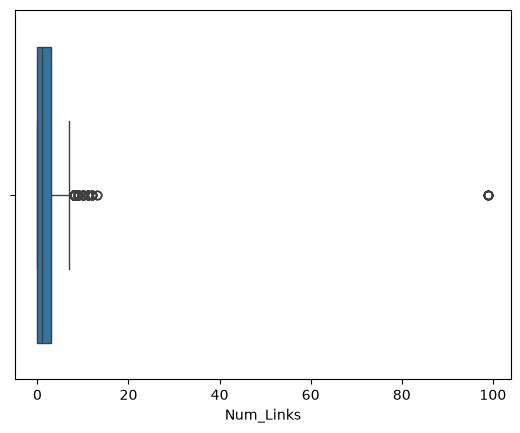

In [21]:
sns.boxplot(data['Num_Links'],orient='h')

In [22]:
data.shape

(7000, 8)

In [23]:
sorted(data['Num_Links'],reverse = True)[:30]

[99,
 99,
 99,
 99,
 99,
 99,
 99,
 99,
 99,
 99,
 99,
 99,
 99,
 99,
 99,
 99,
 99,
 13,
 13,
 13,
 12,
 12,
 12,
 12,
 12,
 12,
 12,
 12,
 12,
 11]

In [24]:
data = data[~(data['Num_Links']>=99)]

In [25]:
sorted(data['Num_Links'],reverse = True)[:30]

[13,
 13,
 13,
 12,
 12,
 12,
 12,
 12,
 12,
 12,
 12,
 12,
 11,
 11,
 11,
 11,
 11,
 11,
 11,
 11,
 11,
 11,
 11,
 11,
 11,
 11,
 11,
 11,
 11,
 11]

In [26]:
sorted(data['Num_Special_Chars'])[:30]

[-1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]

In [27]:
data = data[~(data['Num_Special_Chars']<0)]

In [28]:
sorted(data['Num_Special_Chars'])[:30]

[0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]

In [29]:
data.shape

(6961, 8)

### Encoding Categorical Column

In [30]:
data.head(1)

,Subject,Email_Length,Num_Links,Num_Special_Chars,Capital_Words,Has_Attachment,Spam,Sender_Domain
1,Security Alert,87.0,2,3,8,0,0,outlook.com


In [31]:
data['Subject'].unique()

<ArrowStringArray>
[      'Security Alert',            'Win Prize',              'Invoice',
              'Meeting',                'Offer',       'Project Update',
            'Greetings', 'Account Verification']
Length: 8, dtype: str

In [32]:
data['Subject'] = data['Subject'].map({'Security Alert':0,'Win Prize':1,'Invoice':2,'Meeting':3,'Offer':4,'Project Update':5,'Greetings':6,'Account Verification':7})

In [33]:
data['Subject'].unique()

array([0, 1, 2, 3, 4, 5, 6, 7])

In [34]:
data['Sender_Domain'].unique()

array(['outlook.com', 'yahoo.com', 'gmail.com', 'company.com', 'unknown'],
      dtype=object)

In [35]:
data['Sender_Domain'] = data['Sender_Domain'].map({'outlook.com':0,'yahoo.com':1,'gmail.com':2,'company.com':3,'unknown':4})

In [36]:
data['Sender_Domain'].unique()

array([0, 1, 2, 3, 4])

In [37]:
data['Sender_Domain'].unique()

array([0, 1, 2, 3, 4])

In [38]:
data.head()

,Subject,Email_Length,Num_Links,Num_Special_Chars,Capital_Words,Has_Attachment,Spam,Sender_Domain
1,0,87.0,2,3,8,0,0,0
2,1,69.0,0,3,8,0,0,1
3,2,61.0,0,3,8,0,0,2
4,3,99.0,2,3,5,0,0,3
5,2,52.0,5,1,8,1,0,2


### Store Feature matrix in X and Response (Target) in Vector Y

In [39]:
X = data.drop('Spam',axis=1)
Y = data['Spam']

In [40]:
X

,Subject,Email_Length,Num_Links,Num_Special_Chars,Capital_Words,Has_Attachment,Sender_Domain
1,0,87.0,2,3,8,0,0
2,1,69.0,0,3,8,0,1
3,2,61.0,0,3,8,0,2
4,3,99.0,2,3,5,0,3
5,2,52.0,5,1,8,1,2
...,...,...,...,...,...,...,...
6995,6,93.0,1,2,6,1,2
6996,4,107.0,0,0,7,0,1
6997,7,222.0,7,14,17,0,2
6998,1,164.0,6,16,8,1,0


### Spliting the Dataset into the Training and Test set

In [41]:
from sklearn.model_selection import train_test_split

In [42]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.20,random_state=42)

In [43]:
X_test

,Subject,Email_Length,Num_Links,Num_Special_Chars,Capital_Words,Has_Attachment,Sender_Domain
1343,3,99.0,1,3,2,1,2
5710,7,174.0,5,18,8,0,2
6040,0,114.0,2,6,2,0,2
38,0,82.0,1,1,8,0,0
5668,5,148.0,5,23,30,1,1
...,...,...,...,...,...,...,...
536,7,84.0,0,2,8,0,3
2388,6,66.0,0,3,6,0,2
2197,3,181.0,5,18,15,0,1
656,2,143.0,1,12,38,1,0


In [44]:
X_test.shape

(1393, 7)

### Model Training

In [45]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train,Y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [46]:
rf = RandomForestClassifier()
rf.fit(X_train,Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [47]:
gbc = GradientBoostingClassifier()
gbc.fit(X_train,Y_train)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init init: estimator or 'zero', default=NoneAn estimator object that is used to co

In [48]:
xg = XGBClassifier()
xg.fit(X_train,Y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


### Prediction on Test Data

In [49]:
Y_pred1 = lr.predict(X_test)
Y_pred2 = rf.predict(X_test)
Y_pred3 = gbc.predict(X_test)
Y_pred4 = xg.predict(X_test)

In [50]:
X_test.head()

,Subject,Email_Length,Num_Links,Num_Special_Chars,Capital_Words,Has_Attachment,Sender_Domain
1343,3,99.0,1,3,2,1,2
5710,7,174.0,5,18,8,0,2
6040,0,114.0,2,6,2,0,2
38,0,82.0,1,1,8,0,0
5668,5,148.0,5,23,30,1,1


In [51]:
Y_test

1343    0
5710    1
6040    0
38      0
5668    1
       ..
536     0
2388    0
2197    1
656     1
34      0
Name: Spam, Length: 1393, dtype: int64

In [52]:
Y_pred1

array([0, 1, 0, ..., 1, 1, 0], shape=(1393,))

### Evaluating the Algorithm

In [53]:
from sklearn import metrics

In [54]:
from xgboost import XGBClassifier     

In [55]:
Y_pred4 = xg.predict(X_test)
score4 = metrics.accuracy_score(Y_test,Y_pred4)

In [56]:
score1 = metrics.accuracy_score(Y_test,Y_pred1)
score2 = metrics.accuracy_score(Y_test,Y_pred2)
score3 = metrics.accuracy_score(Y_test,Y_pred3)
score4 = metrics.accuracy_score(Y_test,Y_pred4)

In [57]:
print(score1,score2,score3,score4)

0.9992821249102656 0.9992821249102656 0.9992821249102656 0.9992821249102656


In [58]:
final_data = pd.DataFrame({'Models':['LR','RF','GBC','XG'],
                            "ACCURACY":[score1,score2,score3,score4]})

In [59]:
final_data

,Models,ACCURACY
0,LR,0.999282
1,RF,0.999282
2,GBC,0.999282
3,XG,0.999282


<Axes: xlabel='Models', ylabel='ACCURACY'>

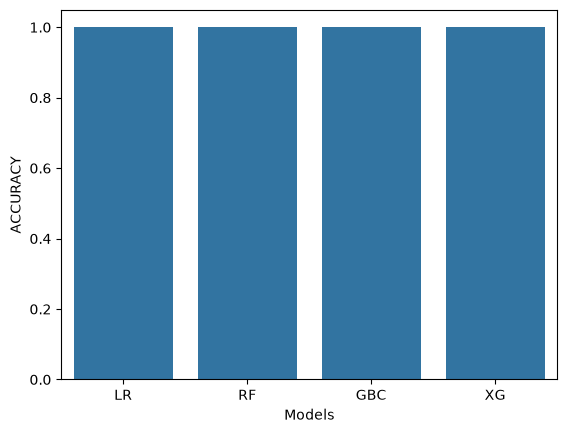

In [60]:
sns.barplot(x=final_data['Models'], y=final_data['ACCURACY'])

In [61]:
precision = [metrics.precision_score(Y_test,p) for p in [Y_pred1,Y_pred2,Y_pred3,Y_pred4]]
recall = [metrics.recall_score(Y_test,p) for p in [Y_pred1,Y_pred2,Y_pred3,Y_pred4]]
f1 = [metrics.f1_score(Y_test,p) for p in [Y_pred1,Y_pred2,Y_pred3,Y_pred4]]

In [62]:
final_data['PRECISION'] = precision
final_data['RECALL'] = recall
final_data['F1_SCORE'] = f1

### Save the Model

In [63]:
lr = LogisticRegression(max_iter=1000)
lr_final = lr.fit(X,Y)

In [64]:
import joblib

In [65]:
joblib.dump(lr_final,'spam_detector')

['spam_detector']

In [66]:
model = joblib.load('spam_detector')

### Prediction on New Data

In [67]:
data.head(1)

,Subject,Email_Length,Num_Links,Num_Special_Chars,Capital_Words,Has_Attachment,Spam,Sender_Domain
1,0,87.0,2,3,8,0,0,0


In [68]:
import pandas as pd
data_new = pd.DataFrame({'Subject':1,'Email_Length':230,'Num_Links':6,'Num_Special_Chars':20,'Capital_Words':40,'Has_Attachment':1,'Sender_Domain':1},index=[0])

In [69]:
data_new

,Subject,Email_Length,Num_Links,Num_Special_Chars,Capital_Words,Has_Attachment,Sender_Domain
0,1,230,6,20,40,1,1


In [70]:
p= model.predict(data_new)
p

array([1])

### Save your model in Pkl format to deploy on Streamlit

In [71]:
import pickle

xg_final = XGBClassifier()
xg_final.fit(X,Y)
pickle.dump(xg_final, open('spam_model.pkl','wb'))